In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"

from statannotations.Annotator import Annotator
from itertools import combinations

import statsmodels.formula.api as smf

from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.group_statistics import test_group_differences, calculate_vif
from additives_microbiota.plotting import process_string, process_string_pretty_vars

In [2]:
# # ==== Global config ====
BINARIZE = False


FOOD_COL = "vegetables_fg_eaten"  # set to "fruits_fg_eaten" to switch
FOOD_LABEL = "Vegetables"  # set to "Fruits" to switch
HI_TEXT = "Veg Hi"

# FOOD_COL = "fruits_fg_eaten"
# FOOD_LABEL = "Fruits"
# HI_TEXT = "Fruit Hi"

## Load Metadata

In [3]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

bmi_order = ["Underweight", "Normal", "Overweight", "Obese"]
meta["bmi_cat"] = pd.Categorical(meta["bmi_cat"], categories=bmi_order, ordered=True)

meta["HEI_Quartile"] = meta["HEI_Quartile"].astype("category")
meta["HEI_Quartile"] = meta["HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["daily_HEI_Quartile"] = meta["daily_HEI_Quartile"].astype("category")
meta["daily_HEI_Quartile"] = meta["daily_HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["age_group_2"] = meta["age_group_2"].astype("category")
meta["age_group_2"] = meta["age_group_2"].cat.set_categories(
    ["<35", "35-50", ">50"], ordered=True
)


## Merging with average additive consumption
# meta = meta.merge(k_across_days_avg.reset_index(), on="subject_key")
# meta = meta.merge(food_category_consumption_by_user, on="subject_key")
meta.shape

(975, 265)

#### Plant diversity (optional)

In [4]:
# # ## Merging with plant diversity data

# plant_diversity = pd.read_csv(
#     "../../data/metadata_files/plant_diversity.csv", index_col=0
# )
# plant_diversity.rename(columns={"plant_diversity": "unique_plant_groups"}, inplace=True)

# # ## Merging with plant diversity
# meta = meta.merge(plant_diversity, on="subject_key")

# plant_diversity["unique_plant_groups"].describe()

## Comparison within high Food group consumers with Additives

In [5]:
def identify_high_consumers(df, col1, col2, quantile_threshold=0.75, verbose=True):
    """
    Identify subjects with high consumption of one or both specified columns.
    Adds boolean flags:
      - high_both_{col1}_{col2}
      - high_{col1}
      - high_{col1}_only
    Returns df and dict of subject_key arrays.
    """
    col1_thr = df[col1].quantile(quantile_threshold)
    col2_thr = df[col2].quantile(quantile_threshold)

    high_col1 = df[col1] > col1_thr
    high_col2 = df[col2] > col2_thr
    high_both = high_col1 & high_col2

    # df[f"high_both_{col1}_{col2}"] = high_both
    group_col = f"high_both_{col1}_{col2}"
    df[group_col] = np.where(high_both, "High", "Low")
    df[group_col] = pd.Categorical(
        df[group_col], categories=["Low", "High"], ordered=True
    )

    df[f"high_{col1}"] = high_col1
    df[f"high_{col1}_only"] = high_col1 & (~high_both)

    high_both_subjects = df.loc[high_both, "subject_key"].to_numpy()
    high_col1_subjects = df.loc[high_col1, "subject_key"].to_numpy()
    high_col1_only_subjects = df.loc[high_col1 & (~high_both), "subject_key"].to_numpy()

    if verbose:
        print(
            f"Number of subjects with high {col1} and {col2} consumption: {high_both.sum()}"
        )
        print(f"Number of subjects with high {col1} consumption: {high_col1.sum()}")
        print(df[f"high_both_{col1}_{col2}"].value_counts())
        print(df[f"high_{col1}"].value_counts())

    return df, {
        "high_both_subjects": high_both_subjects,
        "high_col1_subjects": high_col1_subjects,
        "high_col1_only_subjects": high_col1_only_subjects,
    }

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Low vs. High: Mann-Whitney-Wilcoxon test two-sided, P_val:2.956e-04 U_stat=6.376e+03
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Low vs. High: Mann-Whitney-Wilcoxon test two-sided, P_val:2.933e-03 U_stat=6.256e+03
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Low vs. High: Mann-Whitney-Wilcoxon test two-sided, P_val:2.692e-02 U_stat=5.252e+03
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
  

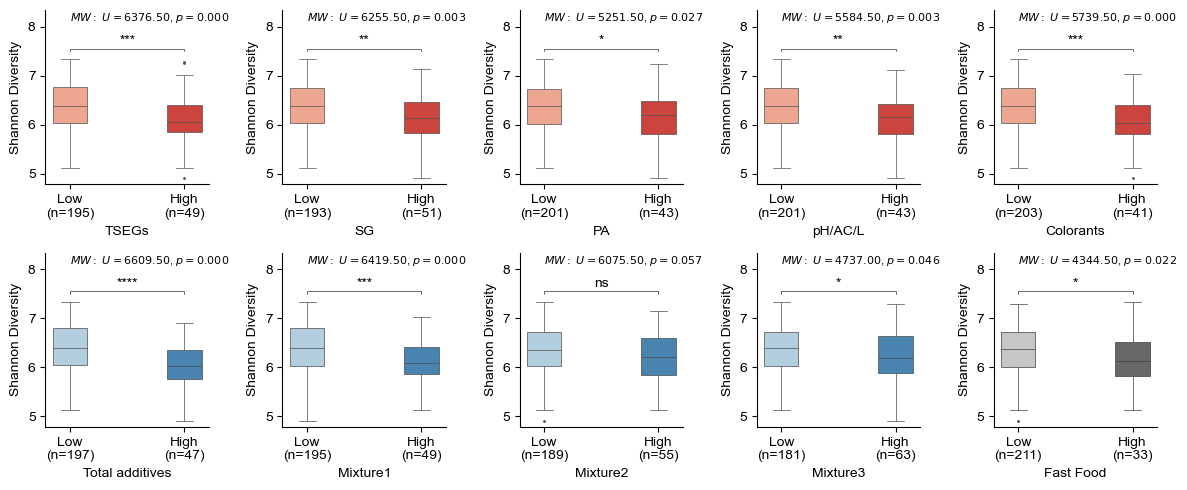

In [6]:
fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(12, 5))

ax = ax.flatten()

col1 = FOOD_COL
meta_subset = meta.copy()

col2_list = (
    [var for var in ADDITIVE_VARS if var not in ["other_additives", "flavor_enhancers"]]
    # additive_vars
    + ["total_additive_intake"]
    + MIXTURES
    + ["fast_food_fg_eaten"]
)

for i, col2 in enumerate(col2_list):
    meta_subset, result = identify_high_consumers(
        meta_subset, col1, col2, 0.75, verbose=False
    )
    test_group_differences(
        meta_subset[meta_subset["subject_key"].isin(result["high_col1_subjects"])],
        f"high_both_{col1}_{col2}",
        "shannon_entropy",
        showfliers=True,
        # palette="Reds" if col2 in additive_vars else "Blues",
        palette=(
            "Reds"
            if col2 in ADDITIVE_VARS
            else ("Greys" if col2 == "fast_food_fg_eaten" else "Blues")
        ),
        ax=ax[i],
        verbose=False,
        xlabel=process_string_pretty_vars(col2, newLineSep=3),
        box_width=0.3,
        ylabel="Shannon Diversity",
    )

sns.despine()
plt.tight_layout()

plt.savefig(
    f"../figures/additive_descriptive/group_comparison_additive_types_by_high_{FOOD_LABEL}.png",
    dpi=300,
    bbox_inches="tight",
)

## Statsmodels for High Food Group and Additives

In [7]:
# ==== OLS: food x additive interaction ====
def ols_food_additive_interaction(
    df,
    outcome_col="shannon_entropy",
    food_col=FOOD_COL,
    additive_col="total_additive_intake",
    covariates=None,
    categorical_covariates=None,
    binarize=True,
    quantile=0.75,
    robust="HC3",
    return_data=False,
):
    d = df.copy()
    covariates = covariates or []
    categorical_covariates = categorical_covariates or []

    if binarize:
        f_thr = d[food_col].quantile(quantile)
        a_thr = d[additive_col].quantile(quantile)
        d["_food_hi"] = (d[food_col] > f_thr).astype(int)
        d["_add_hi"] = (d[additive_col] > a_thr).astype(int)
        inter_terms = ["_food_hi", "_add_hi", "_food_hi:_add_hi"]
        rhs_core = " + ".join(inter_terms)
        thresholds = {"food_threshold": f_thr, "additive_threshold": a_thr}
    else:
        d["_food_z"] = (d[food_col] - d[food_col].mean()) / d[food_col].std(ddof=0)
        d["_add_z"] = (d[additive_col] - d[additive_col].mean()) / d[additive_col].std(
            ddof=0
        )
        inter_terms = ["_food_z", "_add_z", "_food_z:_add_z"]
        rhs_core = " + ".join(inter_terms)
        thresholds = None

    cov_terms = [f"C({c})" if c in categorical_covariates else c for c in covariates]
    rhs = rhs_core if not cov_terms else rhs_core + " + " + " + ".join(cov_terms)
    formula = f"{outcome_col} ~ {rhs}"

    model = (
        smf.ols(formula=formula, data=d).fit(cov_type=robust)
        if robust
        else smf.ols(formula=formula, data=d).fit()
    )

    coef_names = inter_terms + cov_terms
    summary_rows = []
    for name in model.params.index:
        if (
            name == "Intercept"
            or name in coef_names
            or any(name.startswith(f"C({c})") for c in categorical_covariates)
        ):
            summary_rows.append(
                {
                    "term": name,
                    "coef": model.params[name],
                    "se": model.bse[name],
                    "t": model.tvalues[name],
                    "p": model.pvalues[name],
                }
            )

    results = {
        "formula": formula,
        "n": int(model.nobs),
        "r2": float(model.rsquared),
        "r2_adj": float(model.rsquared_adj),
        "robust_SE": bool(robust),
        "thresholds": thresholds,
        "key_terms": summary_rows,
    }

    return (model, results, d) if return_data else (model, results)


# ==== Simple effects for 2x2 (binarized models) ====
def simple_effects(model, binarize=True, food_var=None, add_var=None):
    params = model.params

    def get(name):
        return params[name] if name in params.index else 0.0

    if binarize:
        food_var = food_var or "_food_hi"
        add_var = add_var or "_add_hi"
        inter = f"{food_var}:{add_var}"
        b0 = get("Intercept")
        bF = get(food_var)
        bA = get(add_var)
        bI = get(inter) or get(f"{add_var}:{food_var}")

        return {
            "cell_means": {
                "lowFood_lowAdd": b0,
                "highFood_lowAdd": b0 + bF,
                "lowFood_highAdd": b0 + bA,
                "highFood_highAdd": b0 + bF + bA + bI,
            },
            "simple_effects": {
                "food_effect_at_lowAdd": bF,
                "food_effect_at_highAdd": bF + bI,
                "interaction_delta": bI,
            },
        }

    # Continuous (z) version: effect of food at add_z = -1, 0, +1
    food_var = food_var or "_food_z"
    add_var = add_var or "_add_z"
    inter = f"{food_var}:{add_var}"
    bF = get(food_var)
    bI = get(inter) or get(f"{add_var}:{food_var}")

    return {
        "simple_effects": {
            "food_effect_at_add_minus1sd": bF - bI,
            "food_effect_at_add_mean": bF,
            "food_effect_at_add_plus1sd": bF + bI,
            "interaction_delta_per_1sd_add": bI,
        }
    }

In [8]:
def forest_plot(
    results,
    ignore_features=None,
    highlight=None,
    title="",
    figsize=(5, 4),
    food_label=FOOD_LABEL,
    hi_text="FOOD Hi",
    color_bar="black",
):
    ci = results.conf_int(alpha=0.05)
    dfp = pd.DataFrame({"coef": results.params, "lower": ci[0], "upper": ci[1]}).drop(
        "Intercept", errors="ignore"
    )
    # if features is not None:
    #     dfp = dfp.loc[[f for f in features if f in dfp.index]]
    if ignore_features is not None:
        dfp = dfp.drop(ignore_features, errors="ignore")

    # hi_text = "Veg Hi" if food_label.lower().startswith("veg") else "Fruit Hi"

    label_mapping = {
        "gender[T.male]": "Gender (Male)",
        "language[T.latin]": "Language (Latin)",
        "urbanity[T.semi_urban]": "Urbanity (Semi-Urban)",
        "urbanity[T.urban]": "Urbanity (Urban)",
        "smoking[T.non-smoker]": "Smoking (Non-smoker)",
        "smoking[T.smoker]": "Smoking (Smoker)",
        "antibiotics_treatment[T.True]": "Antibiotics Treatment",
        "_food_hi": hi_text,
        "_add_hi": "Add Hi",
        "_food_hi:_add_hi": f"{hi_text} × Add Hi",
        "_food_z": f"{food_label} (z)",
        "_add_z": "Additives (z)",
        "_food_z:_add_z": f"{food_label} × Additives",
        "age": "Age",
        "bmi": "BMI",
        "HEI": "HEI",
        "defecate_quantity_per_day": "Defecation Frequency",
        "eaten_quantity_in_gram": "Total Eaten Quantity (g/day)",
        "energy_kcal_eaten": "Energy (kcal/day)",
        "alcohol_eaten": "Alcohol (g/day)",
        "fast_food_fg_eaten": "Fast Food (g/day)",
        "vegetables_fg_eaten": "Vegetables (g/day)",
        "vegetables_z": "Vegetables (z)",
    }

    variable_order = [
        "gender[T.male]",
        "age",
        "bmi",
        "language[T.latin]",
        "urbanity[T.semi_urban]",
        "urbanity[T.urban]",
        "smoking[T.non-smoker]",
        "smoking[T.smoker]",
        "antibiotics_treatment[T.True]",
        "defecate_quantity_per_day",
        "HEI",
        "alcohol_eaten",
        "eaten_quantity_in_gram",
        "energy_kcal_eaten",
        "_food_hi:_add_hi",
        "_add_hi",
        "_food_hi",
        "_food_z:_add_z",
        "_add_z",
        "_food_z",
    ]

    existing = [v for v in variable_order if v in dfp.index]
    remaining = [v for v in dfp.index if v not in variable_order]
    dfp = dfp.reindex(existing + remaining)

    err = np.vstack([dfp["coef"] - dfp["lower"], dfp["upper"] - dfp["coef"]])

    fig, ax = plt.subplots(figsize=figsize)
    y = np.arange(len(dfp))
    ax.errorbar(
        dfp["coef"], y, xerr=err, fmt="o", capsize=3, markersize=4, color=color_bar
    )
    if highlight in dfp.index:
        i = dfp.index.get_loc(highlight)
        ax.plot(dfp.loc[highlight, "coef"], i, "o", ms=7, color="red")

    ax.axvline(0, ls="--", alpha=0.5)
    ax.set_yticks(y)
    ax.set_yticklabels([label_mapping.get(idx, idx) for idx in dfp.index])
    ax.set_xlabel("Coefficient Estimate")
    ax.set_title(title)
    fig.tight_layout()
    try:
        sns.despine()
    except Exception:
        pass
    return fig, ax


# ==== Summarize food x additive interactions across many additives ====
def summarize_interactions(
    df,
    food_col,
    additive_cols,
    covariates=None,
    categorical_covariates=None,
    quantile=0.75,
    robust="HC3",
    binarize=True,
):
    rows = []
    for add_col in additive_cols:
        m, r = ols_food_additive_interaction(
            df=df,
            outcome_col="shannon_entropy",
            food_col=food_col,
            additive_col=add_col,
            covariates=covariates or [],
            categorical_covariates=categorical_covariates or [],
            binarize=binarize,
            quantile=quantile,
            robust=robust,
        )
        if binarize:
            inter = [x for x in r["key_terms"] if x["term"] == "_food_hi:_add_hi"][0]
        else:
            inter = [x for x in r["key_terms"] if x["term"] == "_food_z:_add_z"][0]
        eff = simple_effects(m, binarize=binarize)["simple_effects"]

        row = {
            "feature": add_col,
            "beta_interaction": float(inter["coef"]),
            "se_interaction": float(inter["se"]),
            "p_interaction": float(inter["p"]),
            "ci_low": float(inter["coef"] - 1.96 * inter["se"]),
            "ci_high": float(inter["coef"] + 1.96 * inter["se"]),
        }

        if binarize:
            row.update(
                {
                    "food_effect_lowAdd": float(eff["food_effect_at_lowAdd"]),
                    "food_effect_highAdd": float(eff["food_effect_at_highAdd"]),
                    "delta": float(eff["interaction_delta"]),
                }
            )
        else:
            row.update(
                {
                    "food_effect_add_minus1sd": float(
                        eff["food_effect_at_add_minus1sd"]
                    ),
                    "food_effect_add_mean": float(eff["food_effect_at_add_mean"]),
                    "food_effect_add_plus1sd": float(eff["food_effect_at_add_plus1sd"]),
                    "delta_per_1sd_add": float(eff["interaction_delta_per_1sd_add"]),
                }
            )

        rows.append(row)

    return pd.DataFrame(rows).sort_values("beta_interaction")

In [9]:
base_covariates = [
    "age",
    "bmi",
    "language",
    "gender",
    "defecate_quantity_per_day",
    "urbanity",
    "smoking",
    # "eaten_quantity_in_gram",
    "energy_kcal_eaten",
    "antibiotics_treatment",
    "alcohol_eaten",
    "batch",
]

additive_col_for_forest_plot = "total_additive_intake"

shannon_entropy ~ _food_z + _add_z + _food_z:_add_z + age + bmi + language + gender + defecate_quantity_per_day + urbanity + smoking + energy_kcal_eaten + antibiotics_treatment + alcohol_eaten + batch
{'n': 940, 'r2': 0.20893839014296367, 'r2_adj': 0.19172268590233177}
{'term': 'Intercept', 'coef': np.float64(6.572161520483336), 'se': np.float64(0.16720792737604362), 't': np.float64(39.305322562265964), 'p': np.float64(0.0)}
{'term': '_food_z', 'coef': np.float64(0.07196777499595247), 'se': np.float64(0.01671655284365128), 't': np.float64(4.305180360392595), 'p': np.float64(1.6684974232659394e-05)}
{'term': '_add_z', 'coef': np.float64(-0.050583127313921075), 'se': np.float64(0.01882932401413803), 't': np.float64(-2.6864016613629174), 'p': np.float64(0.007222620552791363)}
{'term': '_food_z:_add_z', 'coef': np.float64(-0.03018783497441831), 'se': np.float64(0.011383475816009422), 't': np.float64(-2.6518996009955877), 'p': np.float64(0.008004033812719734)}
{'term': 'age', 'coef': np.flo

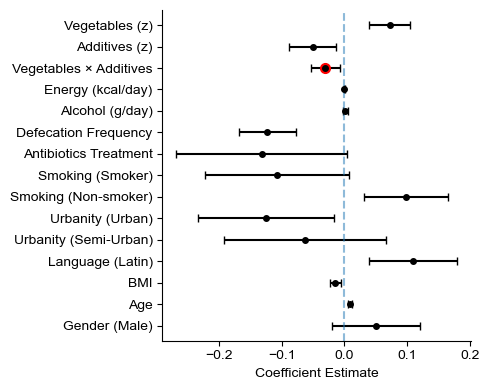

In [10]:
model, res = ols_food_additive_interaction(
    df=meta,
    outcome_col="shannon_entropy",
    food_col=FOOD_COL,
    additive_col=additive_col_for_forest_plot,
    covariates=base_covariates,
    # categorical_covariates=["language","urbanity","smoking","antibiotics_treatment"],
    binarize=BINARIZE,
    quantile=0.75,
    robust="HC3",
    return_data=False,
)


print(res["formula"])
print({"n": res["n"], "r2": res["r2"], "r2_adj": res["r2_adj"]})
for row in res["key_terms"]:
    print(row)

print(model.summary())

summary_path = (
    f"../outputs/supplementary_files/model_summary_total_additive_with_{FOOD_LABEL}.txt"
)
with open(summary_path, "w") as f:
    f.write(model.summary().as_text())

# Forest plot
if additive_col_for_forest_plot == "total_additive_intake":
    forest_plot_title = f"{FOOD_LABEL} benefit moderated by total additives"
else:
    forest_plot_title = (
        f"{FOOD_LABEL} benefit moderated by {additive_col_for_forest_plot}"
    )

fig, ax = forest_plot(
    model,
    highlight="_food_hi:_add_hi" if BINARIZE else "_food_z:_add_z",
    ignore_features=[i for i in model.params.index if "batch" in i],
    # title=forest_plot_title,
    title="",
    food_label=FOOD_LABEL,
    hi_text=HI_TEXT,
)
fig.savefig(
    f"../figures/additive_descriptive/additive_effects_modeling/forest_plot_total_additive_with_{FOOD_LABEL}.png",
    dpi=300,
)

In [11]:
calculate_vif(model)

,variable,VIF
1,language[T.latin],1.216528
2,gender[T.male],1.306258
3,urbanity[T.semi_urban],2.641642
4,urbanity[T.urban],2.677217
5,smoking[T.non-smoker],1.208291
6,smoking[T.smoker],1.173577
7,antibiotics_treatment[T.True],1.026875
8,batch[T.batch_0682],2.441266
9,batch[T.batch_1205],2.586606
10,batch[T.batch_1599],2.748842


In [12]:
# model_cohort_b, res_cohort_b = ols_food_additive_interaction(
#     df=meta[meta["cohort"] == "cohort_b"],
#     outcome_col="shannon_entropy",
#     food_col=FOOD_COL,
#     additive_col=additive_col_for_forest_plot,
#     covariates=base_covariates,
#     # categorical_covariates=["language","urbanity","smoking","antibiotics_treatment"],
#     binarize=BINARIZE,
#     quantile=0.75,
#     robust="HC3",
#     return_data=False,
# )


# print(res_cohort_b["formula"])
# print(model_cohort_b.summary())

In [13]:
# Running across additives
df_eff = summarize_interactions(
    df=meta,
    food_col=FOOD_COL,
    additive_cols=[i for i in ADDITIVE_VARS if i != "other_additives"]
    + ["total_additive_intake"]
    + MIXTURES
    + ["fast_food_fg_eaten"],
    covariates=base_covariates,
    # categorical_covariates=["language", "urbanity", "smoking", "antibiotics_treatment"],
    quantile=0.75,
    binarize=BINARIZE,
)

In [14]:
df_eff

,feature,beta_interaction,se_interaction,p_interaction,ci_low,ci_high,food_effect_add_minus1sd,food_effect_add_mean,food_effect_add_plus1sd,delta_per_1sd_add
0,thickeners_stabilizers_emulsifiers_gelling_agents,-0.042337,0.016443,0.010029,-0.074565,-0.010110,0.110655,0.068317,0.025980,-0.042337
5,colorants,-0.039395,0.017502,0.024387,-0.073698,-0.005092,0.110880,0.071484,0.032089,-0.039395
3,ph_regulators_anti_caking_leavening_agents,-0.037177,0.023424,0.112487,-0.083088,0.008734,0.098432,0.061256,0.024079,-0.037177
6,total_additive_intake,-0.030188,0.011383,0.008004,-0.052499,-0.007876,0.102156,0.071968,0.041780,-0.030188
2,preservatives_antioxidants,-0.027768,0.019488,0.154190,-0.065964,0.010428,0.098538,0.070770,0.043002,-0.027768
1,sweeteners_glazing_agents,-0.020844,0.008795,0.017790,-0.038083,-0.003606,0.095780,0.074936,0.054092,-0.020844
9,Mixture3,-0.018044,0.007027,0.010235,-0.031817,-0.004271,0.093387,0.075343,0.057299,-0.018044
7,Mixture1,-0.017759,0.018258,0.330705,-0.053545,0.018026,0.073384,0.055625,0.037866,-0.017759
8,Mixture2,-0.013156,0.016204,0.416822,-0.044916,0.018603,0.072625,0.059469,0.046312,-0.013156
4,flavor_enhancers,-0.006972,0.016377,0.670328,-0.039071,0.025128,0.067506,0.060535,0.053563,-0.006972


In [15]:
# ==== Plot: interaction summary (keeps original naming pattern) ====
def plot_interaction_summary(
    df_eff,
    title="",
    figsize=(6, max(3, 0.35 * len(df_eff))),
    food_label=FOOD_LABEL,
    bar_color="green",
):
    d = df_eff.sort_values("beta_interaction")
    y = np.arange(len(d))
    fig, ax = plt.subplots(figsize=figsize)
    ax.errorbar(
        d["beta_interaction"],
        y,
        xerr=[
            d["beta_interaction"] - d["ci_low"],
            d["ci_high"] - d["beta_interaction"],
        ],
        fmt="o",
        color=bar_color,
        capsize=3,
    )
    ax.axvline(0, ls="--", alpha=0.5)
    ax.set_yticks(y)
    labels = [process_string_pretty_vars(x) for x in d["feature"]]
    ax.set_yticklabels(labels)
    if food_label == "Vegetables":
        left = "Veg"
    elif food_label == "Fruits":
        left = "Fruit"
    else:
        left = food_label
    ax.set_xlabel(f"Interaction beta ({left} × additive), 95% CI")
    ax.set_title(title or f"{food_label} benefit moderated by additives", fontsize=11)
    fig.tight_layout()
    try:
        sns.despine()
    except Exception:
        pass
    return fig, ax

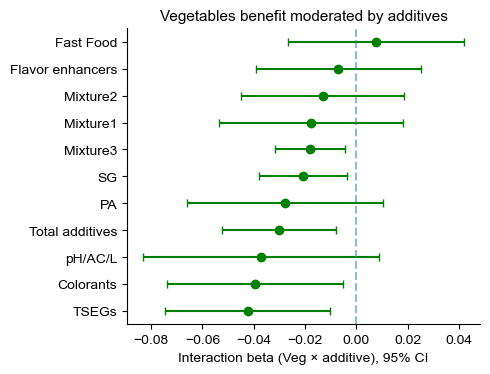

In [16]:
df_eff.to_csv(
    f"../outputs/supplementary_files/food_additives_interaction_summary_with_high_{FOOD_LABEL}.csv",
    index=False,
)

# Summary plots
fig1, ax1 = plot_interaction_summary(
    df_eff,
    figsize=(5, max(3, 0.35 * len(df_eff))),
    title="",
    food_label=FOOD_LABEL,
)
fig1.savefig(
    f"../figures/additive_descriptive/additive_effects_modeling/food_additive_interaction_summary_with_{FOOD_LABEL}.png",
    dpi=300,
    bbox_inches="tight",
)

# Test fast food effects

In [17]:
meta_fast_food = meta.copy()
meta_fast_food["vegetables_z"] = (
    meta_fast_food["vegetables_fg_eaten"] - meta_fast_food["vegetables_fg_eaten"].mean()
) / meta_fast_food["vegetables_fg_eaten"].std(ddof=0)

model_fast_food, res_fast_food = ols_food_additive_interaction(
    df=meta_fast_food,
    outcome_col="shannon_entropy",
    food_col="fast_food_fg_eaten",
    additive_col="total_additive_intake",
    covariates=base_covariates + ["vegetables_z"],
    binarize=False,
    quantile=0.75,
    robust="HC3",
    return_data=False,
)

print(model_fast_food.summary())

                            OLS Regression Results                            
Dep. Variable:        shannon_entropy   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.186
Method:                 Least Squares   F-statistic:                     11.57
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.14e-34
Time:                        09:10:17   Log-Likelihood:                -636.93
No. Observations:                 940   AIC:                             1318.
Df Residuals:                     918   BIC:                             1424.
Df Model:                          21                                         
Covariance Type:                  HC3                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [18]:
calculate_vif(model_fast_food)

,variable,VIF
1,language[T.latin],1.218153
2,gender[T.male],1.346866
3,urbanity[T.semi_urban],2.630038
4,urbanity[T.urban],2.670284
5,smoking[T.non-smoker],1.208373
6,smoking[T.smoker],1.175182
7,antibiotics_treatment[T.True],1.030655
8,batch[T.batch_0682],2.442384
9,batch[T.batch_1205],2.591134
10,batch[T.batch_1599],2.749164


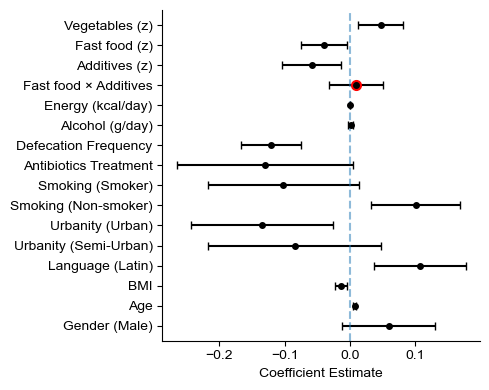

In [19]:
with open(
    "../outputs/supplementary_files/model_summary_total_additive_with_Fast_food.txt",
    "w",
) as f:
    f.write(model_fast_food.summary().as_text())

fig, ax = forest_plot(
    model_fast_food,
    highlight="_food_z:_add_z",
    ignore_features=[i for i in model_fast_food.params.index if "batch" in i],
    # title=forest_plot_title,
    title="",
    food_label="Fast food",
    hi_text=None,
)
fig.savefig(
    f"../figures/additive_descriptive/additive_effects_modeling/forest_plot_total_additive_with_Fast_food.png",
    dpi=300,
)

## Testing with sugar intake

In [20]:
meta_sugar = meta.copy()
meta_sugar["vegetables_z"] = (
    meta_sugar["vegetables_fg_eaten"] - meta_sugar["vegetables_fg_eaten"].mean()
) / meta_sugar["vegetables_fg_eaten"].std(ddof=0)
meta_sugar["sugar_z"] = (
    meta_sugar["sugar_eaten"] - meta_sugar["sugar_eaten"].mean()
) / meta_sugar["sugar_eaten"].std(ddof=0)

model_sugar, res_sugar = ols_food_additive_interaction(
    df=meta_sugar,
    outcome_col="shannon_entropy",
    food_col="fast_food_fg_eaten",
    additive_col="total_additive_intake",
    covariates=base_covariates + ["vegetables_z", "sugar_z"],
    binarize=False,
    quantile=0.75,
    robust="HC3",
    return_data=False,
)

print(model_sugar.summary())

                            OLS Regression Results                            
Dep. Variable:        shannon_entropy   R-squared:                       0.206
Model:                            OLS   Adj. R-squared:                  0.187
Method:                 Least Squares   F-statistic:                     11.15
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.53e-34
Time:                        09:10:17   Log-Likelihood:                -635.66
No. Observations:                 940   AIC:                             1317.
Df Residuals:                     917   BIC:                             1429.
Df Model:                          22                                         
Covariance Type:                  HC3                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [21]:
calculate_vif(model_sugar)

,variable,VIF
1,language[T.latin],1.220464
2,gender[T.male],1.357406
3,urbanity[T.semi_urban],2.631917
4,urbanity[T.urban],2.670818
5,smoking[T.non-smoker],1.210264
6,smoking[T.smoker],1.175393
7,antibiotics_treatment[T.True],1.033642
8,batch[T.batch_0682],2.445243
9,batch[T.batch_1205],2.591316
10,batch[T.batch_1599],2.751193
